In [16]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
import warnings
from pathlib import Path
from scripts.data_loading import read_all
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [17]:
REPO_ROOT = Path.cwd().parent
TRAIN = REPO_ROOT / "data" / "train"

train_input = read_all(TRAIN, "input_*.csv")
train_output = read_all(TRAIN, "output_*.csv")

KEYS = ["game_id", "play_id", "nfl_id"]

train/input_*.csv: found 18 files
train/output_*.csv: found 18 files


In [18]:
warnings.filterwarnings("ignore")

def split_by_game(inp, out, test_frac=0.2, seed=42):
    games = inp["game_id"].unique().copy()
    np.random.default_rng(seed).shuffle(games)
    test_games = set(games[:int(len(games) * test_frac)])

    in_test = inp["game_id"].isin(test_games)
    out_test = out["game_id"].isin(test_games)

    return (
        inp[~in_test].reset_index(drop=True),
        inp[in_test].reset_index(drop=True),
        out[~out_test].reset_index(drop=True),
        out[out_test].reset_index(drop=True),
    )


train_in, test_in, train_out, test_out = split_by_game(
    train_input, train_output
)

print(
    "Test games:", test_in["game_id"].nunique(),
    "| Test plays:", test_in[["game_id", "play_id"]].drop_duplicates().shape[0]
)

Test games: 54 | Test plays: 2765


In [19]:
warnings.filterwarnings("ignore")

def forecast_series(values, n, order=(1, 1, 0)):
    values = np.asarray(values, dtype=float)

    if len(values) < 3:
        return np.full(n, values[-1])

    try:
        return np.asarray(ARIMA(values, order=order).fit().forecast(n))
    except Exception:
        return np.full(n, values[-1])

In [20]:
warnings.filterwarnings("ignore")

def forecast_players(inp, horizons, order=(1, 1, 0)):
    rows = []

    for key, g in inp.sort_values("frame_id").groupby(KEYS):
        if key not in horizons.index:
            continue

        n = int(horizons.loc[key])
        rows.append(pd.DataFrame({
            **dict(zip(KEYS, key)),
            "frame_id": np.arange(1, n + 1),
            "x_pred": forecast_series(g["x"], n, order),
            "y_pred": forecast_series(g["y"], n, order),
        }))

    return pd.concat(rows, ignore_index=True)


horizons = test_out.groupby(KEYS).size()
preds = forecast_players(test_in, horizons)

In [21]:
test_out = test_out.merge(
    preds, on=KEYS + ["frame_id"], how="left"
)

print("Rows without prediction:", test_out["x_pred"].isna().sum())
display(test_out.head())

Rows without prediction: 0


,game_id,play_id,nfl_id,frame_id,x,y,source_file,x_pred,y_pred
0,2023091002,110,53455,1,54.47,38.42,output_2023_w01,54.478392,38.417833
1,2023091002,110,53455,2,54.57,38.58,output_2023_w01,54.595197,38.563530
2,2023091002,110,53455,3,54.67,38.75,output_2023_w01,54.710437,38.707121
3,2023091002,110,53455,4,54.75,38.95,output_2023_w01,54.824132,38.848639
4,2023091002,110,53455,5,54.82,39.19,output_2023_w01,54.936304,38.988111


In [26]:
err = np.sqrt(((test_out["x"] - test_out["x_pred"]) ** 2 + (test_out["y"] - test_out["y_pred"]) ** 2).mean() / 2)
print("RMSE:", err)

RMSE: 1.8107152731829819


In [27]:
def draw_field(ax):
    ax.set(xlim=(0, 120), ylim=(0, 53.3), xlabel="x (yards)", ylabel="y (yards)")
    ax.set_aspect("equal")
    ax.add_patch(Rectangle((0, 0), 120, 53.3, color="#3a7d44", zorder=0))
    ax.add_patch(Rectangle((0, 0), 10, 53.3, color="#2c5f34", zorder=0))
    ax.add_patch(Rectangle((110, 0), 10, 53.3, color="#2c5f34", zorder=0))

    for x in range(10, 111, 5):
        ax.axvline(x, color="white", lw=0.8 if x % 10 == 0 else 0.4,
                   alpha=0.7, zorder=1)


def plot_play(game_id, play_id, test_in, test_out):
    inp = test_in.query("game_id == @game_id and play_id == @play_id")
    out = test_out.query("game_id == @game_id and play_id == @play_id")

    if inp.empty:
        print("Play not found.")
        return

    fig, ax = plt.subplots(figsize=(14, 6.5))
    draw_field(ax)

    for nfl_id, g in inp.sort_values("frame_id").groupby("nfl_id"):
        o = out[out["nfl_id"] == nfl_id].sort_values("frame_id")
        name = g["player_name"].iloc[0]
        lx, ly = g["x"].iloc[-1], g["y"].iloc[-1]

        ax.plot(g["x"], g["y"], color="tab:blue", lw=1.8, zorder=3)

        if not o.empty:
            ax.plot([lx, *o["x"]], [ly, *o["y"]],
                    color="lime", lw=1.8, zorder=3)

            if o["x_pred"].notna().any():
                ax.plot([lx, *o["x_pred"]], [ly, *o["y_pred"]],
                        color="red", lw=1.8, ls="--", zorder=3)

        ax.scatter(lx, ly, s=25, color="white",
                   edgecolor="black", zorder=4)
        ax.annotate(name.split()[-1], (lx, ly), fontsize=7,
                    color="white", xytext=(3, 3),
                    textcoords="offset points")

    bx = inp["ball_land_x"].iloc[0]
    by = inp["ball_land_y"].iloc[0]
    ax.scatter(bx, by, marker="*", s=200, color="gold",
               edgecolor="black", zorder=5)

    ax.plot([], [], color="tab:blue", label="Input")
    ax.plot([], [], color="lime", label="True output")
    ax.plot([], [], color="red", ls="--", label="Predicted output")
    ax.scatter([], [], marker="*", s=120, color="gold",
               edgecolor="black", label="Ball landing")

    ax.legend(loc="upper right", fontsize=8)
    ax.set_title(f"Game {game_id}, Play {play_id}")
    plt.tight_layout()
    plt.show()

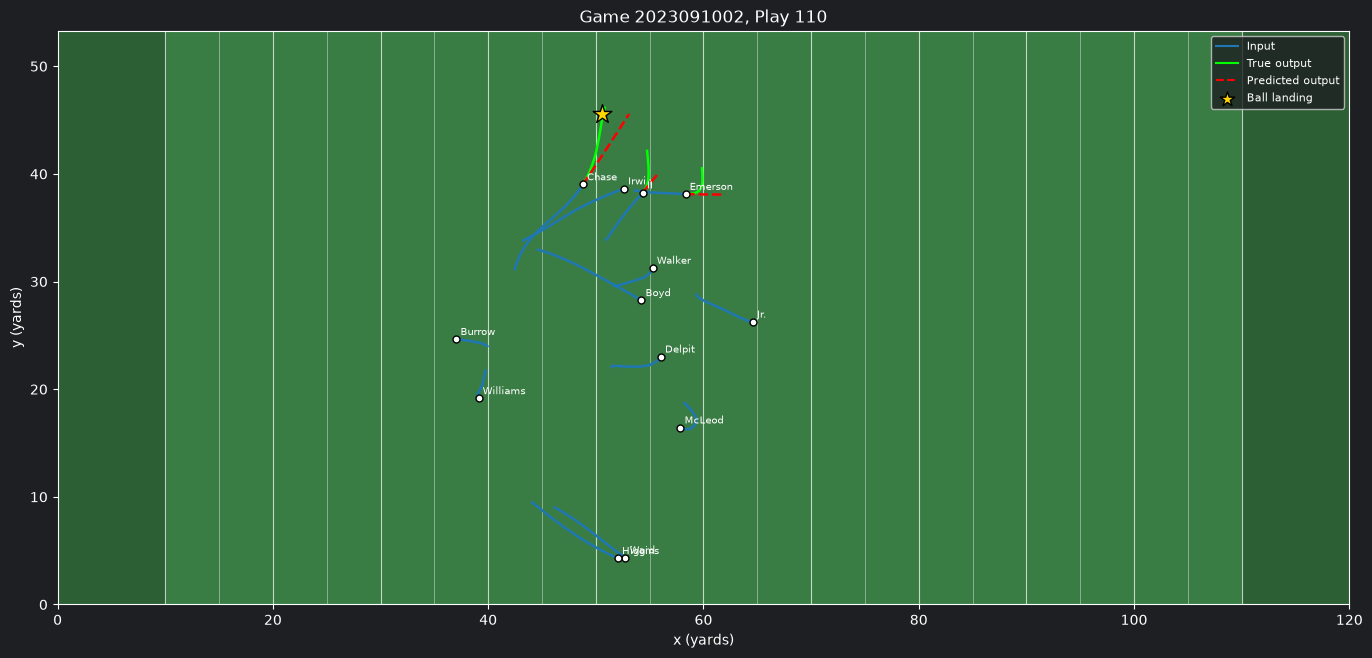

In [28]:
# first play in the test set
g0, p0 = test_in[["game_id", "play_id"]].iloc[0]
plot_play(g0, p0, test_in, test_out)

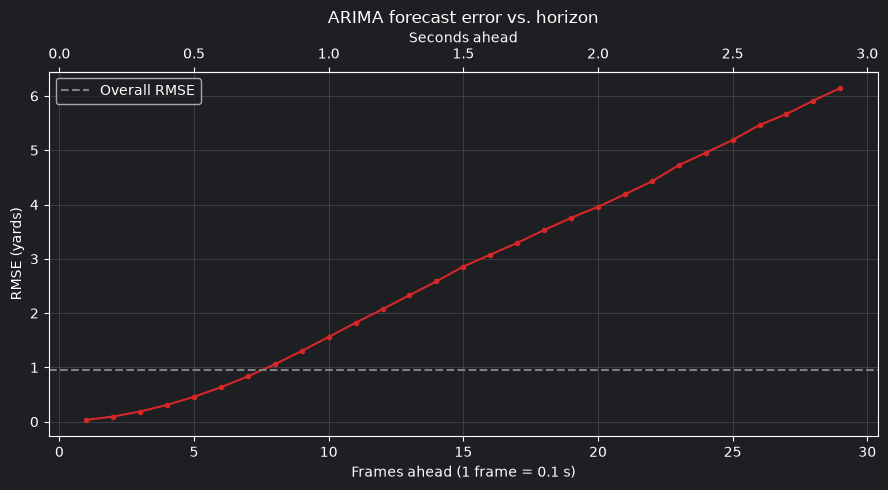

              rmse  count
frame_id                 
1         0.032849   8986
5         0.458775   8986
10        1.561063   5532
20        3.958067   1044
30        6.427121     89


In [30]:
test_out["se"] = ((test_out["x"] - test_out["x_pred"]) ** 2 +
                  (test_out["y"] - test_out["y_pred"]) ** 2)

by_h = test_out.groupby("frame_id")["se"].agg(["mean", "count"])
by_h["rmse"] = np.sqrt(by_h["mean"] / 2)

MIN_ROWS = 100
plot_df = by_h[by_h["count"] >= MIN_ROWS]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(plot_df.index, plot_df["rmse"], marker="o", ms=3, color="tab:red")
ax.axhline(np.sqrt(err.mean() / 2), color="gray", ls="--", label="Overall RMSE")
ax.set_xlabel("Frames ahead (1 frame = 0.1 s)")
ax.set_ylabel("RMSE (yards)")
ax.set_title("ARIMA forecast error vs. horizon")
ax.grid(alpha=0.3)
ax.legend()

secax = ax.secondary_xaxis("top", functions=(lambda f: f / 10, lambda s: s * 10))
secax.set_xlabel("Seconds ahead")

plt.tight_layout()
plt.show()

print(by_h.loc[[1, 5, 10, 20, 30], ["rmse", "count"]] if 30 in by_h.index else by_h.head())